In [1]:
import sys
sys.path.insert(0, "..")

from utils.modelling import *
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import average_precision_score

In [2]:
Xtrain, ytrain, Xval, yval, Xtest, ytest = load_train_val_test('../data/processed/dataset.csv', target="y_bin")
BINARY_LABELS = ["Not damaged", "Damaged"]
pd.DataFrame({"train": ytrain.value_counts(), "validation": yval.value_counts(), "test": ytest.value_counts()}).sort_index()

,train,validation,test
y_bin,,,
0,71928,23977,23977
1,5875,1958,1958


In [3]:
GAMMAS = [0, 0.25, 0.5, 0.75, 1.0]
weights = make_class_weights(ytrain)

def make_binary_logistic_grid(model="A"):
    return GridSearchCV(
        make_pipeline(
            make_preprocessor(model=model),
            LogisticRegression(max_iter=1000)
        ),
        cv=5,
        param_grid={
            "logisticregression__class_weight": [weights(g) for g in GAMMAS],
        },
        scoring="f1_macro",
        n_jobs=-1
    )

def make_binary_tree_grid(model="A"):
    return GridSearchCV(
        make_pipeline(
            make_preprocessor(model=model),
            DecisionTreeClassifier(random_state=67)
        ),
        cv=5,
        param_grid={
            "decisiontreeclassifier__max_depth": [3, 5, 8, 12, None],
            "decisiontreeclassifier__min_samples_leaf": [1, 20, 100, 300],
            "decisiontreeclassifier__class_weight": [weights(g) for g in GAMMAS],
        },
        scoring="f1_macro",
        n_jobs=-1
    )

def make_binary_forest_grid(model="A"):
    return RandomizedSearchCV(
        make_pipeline(
            make_preprocessor(model=model),
            RandomForestClassifier(n_estimators=100, random_state=67)
        ),
        cv=5,
        param_distributions={
            "randomforestclassifier__max_depth": [10, 20, None],
            "randomforestclassifier__min_samples_leaf": [1, 10, 50],
            "randomforestclassifier__max_features": ["sqrt", 0.3],
            "randomforestclassifier__class_weight": [weights(g) for g in GAMMAS[:4]],
        },
        n_iter=20,
        random_state=67,
        scoring="f1_macro",
        n_jobs=-1
    )

In [4]:
binary_baseline = make_baseline_model().fit(Xtrain, ytrain)

binary_grids = {}
for model in ["A", "B"]:
    binary_grids[f"Logistic Regression {model}"] = make_binary_logistic_grid(model=model).fit(Xtrain, ytrain)
    binary_grids[f"Decision Tree {model}"] = make_binary_tree_grid(model=model).fit(Xtrain, ytrain)
    binary_grids[f"Random Forest {model}"] = make_binary_forest_grid(model=model).fit(Xtrain, ytrain)

binary_cv = [cv_summary(grid, name) for name, grid in binary_grids.items()]
for name, grid in binary_grids.items():
    print(name, grid.best_params_)

Logistic Regression A: CV macro F1 = 0.7025 +/- 0.0032
Decision Tree A: CV macro F1 = 0.7008 +/- 0.0068
Random Forest A: CV macro F1 = 0.7144 +/- 0.0056
Logistic Regression B: CV macro F1 = 0.7252 +/- 0.0046
Decision Tree B: CV macro F1 = 0.7314 +/- 0.0053
Random Forest B: CV macro F1 = 0.7486 +/- 0.0075
Logistic Regression A {'logisticregression__class_weight': {0: np.float64(1.0), 1: np.float64(3.499008978237586)}}
Decision Tree A {'decisiontreeclassifier__class_weight': {0: np.float64(1.0), 1: np.float64(3.499008978237586)}, 'decisiontreeclassifier__max_depth': 8, 'decisiontreeclassifier__min_samples_leaf': 20}
Random Forest A {'randomforestclassifier__min_samples_leaf': 10, 'randomforestclassifier__max_features': 0.3, 'randomforestclassifier__max_depth': None, 'randomforestclassifier__class_weight': {0: np.float64(1.0), 1: np.float64(3.499008978237586)}}
Logistic Regression B {'logisticregression__class_weight': {0: np.float64(1.0), 1: np.float64(3.499008978237586)}}
Decision Tree 

In [5]:
binary_val = [evaluate_model(binary_baseline, Xval, yval, "Baseline - VAL", labels=BINARY_LABELS)]
for name, grid in binary_grids.items():
    binary_val.append(evaluate_model(grid.best_estimator_, Xval, yval, f"{name} - VAL", labels=BINARY_LABELS))

              precision    recall  f1-score   support

 Not damaged       0.92      1.00      0.96     23977
     Damaged       0.00      0.00      0.00      1958

    accuracy                           0.92     25935
   macro avg       0.46      0.50      0.48     25935
weighted avg       0.85      0.92      0.89     25935
 Model: Baseline - VAL
F1 Macro: 0.4804
Balanced Accuracy: 0.5000
Accuracy: 0.9245
Recall: [1. 0.]
Confusion matrix (rows = true, columns = predicted):
[[23977     0]
 [ 1958     0]]
              precision    recall  f1-score   support

 Not damaged       0.96      0.95      0.95     23977
     Damaged       0.43      0.48      0.46      1958

    accuracy                           0.91     25935
   macro avg       0.69      0.72      0.70     25935
weighted avg       0.92      0.91      0.92     25935
 Model: Logistic Regression A - VAL
F1 Macro: 0.7044
Balanced Accuracy: 0.7158
Accuracy: 0.9129
Recall: [0.94795012 0.48365679]
Confusion matrix (rows = true, column

              precision    recall  f1-score   support

 Not damaged       0.96      0.94      0.95     23977
     Damaged       0.43      0.51      0.46      1958

    accuracy                           0.91     25935
   macro avg       0.69      0.73      0.71     25935
weighted avg       0.92      0.91      0.91     25935
 Model: Decision Tree A - VAL
F1 Macro: 0.7078
Balanced Accuracy: 0.7264
Accuracy: 0.9112
Recall: [0.94411311 0.50868233]
Confusion matrix (rows = true, columns = predicted):
[[22637  1340]
 [  962   996]]


              precision    recall  f1-score   support

 Not damaged       0.96      0.96      0.96     23977
     Damaged       0.48      0.49      0.48      1958

    accuracy                           0.92     25935
   macro avg       0.72      0.72      0.72     25935
weighted avg       0.92      0.92      0.92     25935
 Model: Random Forest A - VAL
F1 Macro: 0.7205
Balanced Accuracy: 0.7226
Accuracy: 0.9212
Recall: [0.95649998 0.48876404]
Confusion matrix (rows = true, columns = predicted):
[[22934  1043]
 [ 1001   957]]
              precision    recall  f1-score   support

 Not damaged       0.96      0.95      0.96     23977
     Damaged       0.47      0.56      0.51      1958

    accuracy                           0.92     25935
   macro avg       0.72      0.75      0.73     25935
weighted avg       0.93      0.92      0.92     25935
 Model: Logistic Regression B - VAL
F1 Macro: 0.7346
Balanced Accuracy: 0.7535
Accuracy: 0.9201
Recall: [0.9497018  0.55720123]
Confusion matr

              precision    recall  f1-score   support

 Not damaged       0.97      0.96      0.96     23977
     Damaged       0.52      0.58      0.55      1958

    accuracy                           0.93     25935
   macro avg       0.74      0.77      0.75     25935
weighted avg       0.93      0.93      0.93     25935
 Model: Random Forest B - VAL
F1 Macro: 0.7539
Balanced Accuracy: 0.7686
Accuracy: 0.9274
Recall: [0.95558243 0.58171604]
Confusion matrix (rows = true, columns = predicted):
[[22912  1065]
 [  819  1139]]


In [6]:
binary_test = [evaluate_model(binary_baseline, Xtest, ytest, "Baseline - TEST", labels=BINARY_LABELS)]
for name, grid in binary_grids.items():
    result = evaluate_model(grid.best_estimator_, Xtest, ytest, f"{name} - TEST", labels=BINARY_LABELS)
    result["pr_auc"] = average_precision_score(ytest, grid.best_estimator_.predict_proba(Xtest)[:, 1])
    binary_test.append(result)
binary_test[0]["pr_auc"] = average_precision_score(ytest, binary_baseline.predict_proba(Xtest)[:, 1])

              precision    recall  f1-score   support

 Not damaged       0.92      1.00      0.96     23977
     Damaged       0.00      0.00      0.00      1958

    accuracy                           0.92     25935
   macro avg       0.46      0.50      0.48     25935
weighted avg       0.85      0.92      0.89     25935
 Model: Baseline - TEST
F1 Macro: 0.4804
Balanced Accuracy: 0.5000
Accuracy: 0.9245
Recall: [1. 0.]
Confusion matrix (rows = true, columns = predicted):
[[23977     0]
 [ 1958     0]]
              precision    recall  f1-score   support

 Not damaged       0.96      0.95      0.95     23977
     Damaged       0.45      0.48      0.46      1958

    accuracy                           0.92     25935
   macro avg       0.70      0.72      0.71     25935
weighted avg       0.92      0.92      0.92     25935
 Model: Logistic Regression A - TEST
F1 Macro: 0.7095
Balanced Accuracy: 0.7166
Accuracy: 0.9162
Recall: [0.95166201 0.48161389]
Confusion matrix (rows = true, colu

              precision    recall  f1-score   support

 Not damaged       0.96      0.94      0.95     23977
     Damaged       0.42      0.50      0.46      1958

    accuracy                           0.91     25935
   macro avg       0.69      0.72      0.71     25935
weighted avg       0.92      0.91      0.91     25935
 Model: Decision Tree A - TEST
F1 Macro: 0.7055
Balanced Accuracy: 0.7237
Accuracy: 0.9107
Recall: [0.94390458 0.50357508]
Confusion matrix (rows = true, columns = predicted):
[[22632  1345]
 [  972   986]]


              precision    recall  f1-score   support

 Not damaged       0.96      0.96      0.96     23977
     Damaged       0.48      0.50      0.49      1958

    accuracy                           0.92     25935
   macro avg       0.72      0.73      0.72     25935
weighted avg       0.92      0.92      0.92     25935
 Model: Random Forest A - TEST
F1 Macro: 0.7219
Balanced Accuracy: 0.7256
Accuracy: 0.9211
Recall: [0.95583267 0.49540347]
Confusion matrix (rows = true, columns = predicted):
[[22918  1059]
 [  988   970]]


              precision    recall  f1-score   support

 Not damaged       0.96      0.95      0.96     23977
     Damaged       0.49      0.55      0.52      1958

    accuracy                           0.92     25935
   macro avg       0.72      0.75      0.74     25935
weighted avg       0.93      0.92      0.92     25935
 Model: Logistic Regression B - TEST
F1 Macro: 0.7369
Balanced Accuracy: 0.7517
Accuracy: 0.9220
Recall: [0.95232932 0.55107252]
Confusion matrix (rows = true, columns = predicted):
[[22834  1143]
 [  879  1079]]
              precision    recall  f1-score   support

 Not damaged       0.96      0.96      0.96     23977
     Damaged       0.51      0.54      0.52      1958

    accuracy                           0.93     25935
   macro avg       0.74      0.75      0.74     25935
weighted avg       0.93      0.93      0.93     25935
 Model: Decision Tree B - TEST
F1 Macro: 0.7424
Balanced Accuracy: 0.7500
Accuracy: 0.9258
Recall: [0.95708387 0.54290092]
Confusion ma

              precision    recall  f1-score   support

 Not damaged       0.97      0.96      0.96     23977
     Damaged       0.52      0.58      0.55      1958

    accuracy                           0.93     25935
   macro avg       0.74      0.77      0.75     25935
weighted avg       0.93      0.93      0.93     25935
 Model: Random Forest B - TEST
F1 Macro: 0.7547
Balanced Accuracy: 0.7697
Accuracy: 0.9275
Recall: [0.95558243 0.58375894]
Confusion matrix (rows = true, columns = predicted):
[[22912  1065]
 [  815  1143]]


In [7]:
results = results_table(binary_val + binary_test, labels=BINARY_LABELS)
results.to_csv("../results/binary.csv", index=False)
pd.DataFrame(binary_cv).to_csv("../results/binary_cv.csv", index=False)
results

,model,f1_macro,bal_acc,accuracy,precision_Not damaged,precision_Damaged,recall_Not damaged,recall_Damaged,f1_Not damaged,f1_Damaged,pr_auc
0,Baseline - VAL,0.480385,0.500000,0.924504,0.924504,0.000000,1.000000,0.000000,0.960771,0.000000,NaN
1,Logistic Regression A - VAL,0.704357,0.715803,0.912898,0.957414,0.431435,0.947950,0.483657,0.952658,0.456056,NaN
2,Decision Tree A - VAL,0.707759,0.726398,0.911240,0.959236,0.426370,0.944113,0.508682,0.951614,0.463903,NaN
3,Random Forest A - VAL,0.720458,0.722632,0.921188,0.958178,0.478500,0.956500,0.488764,0.957338,0.483578,NaN
4,Logistic Regression B - VAL,0.734636,0.753452,0.920069,0.963322,0.474967,0.949702,0.557201,0.956463,0.512808,NaN
5,Decision Tree B - VAL,0.731887,0.738214,0.923115,0.960647,0.491321,0.955999,0.520429,0.958318,0.505456,NaN
6,Random Forest B - VAL,0.753921,0.768649,0.927357,0.965488,0.516788,0.955582,0.581716,0.960510,0.547333,NaN
7,Baseline - TEST,0.480385,0.500000,0.924504,0.924504,0.000000,1.000000,0.000000,0.960771,0.000000,0.075496
8,Logistic Regression A - TEST,0.709530,0.716638,0.916175,0.957412,0.448620,0.951662,0.481614,0.954528,0.464532,0.428538
9,Decision Tree A - TEST,0.705542,0.723740,0.910661,0.958821,0.422994,0.943905,0.503575,0.951304,0.459781,0.415491


## plots

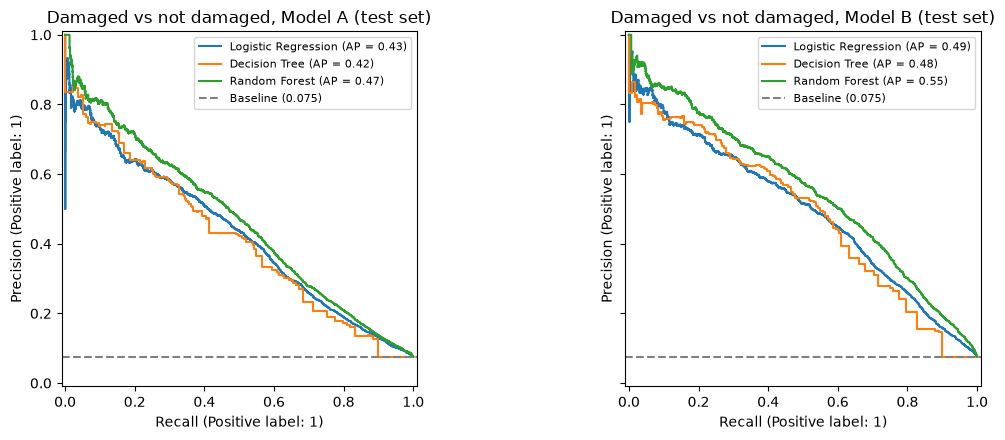

In [8]:
import matplotlib.pyplot as plt
from sklearn.metrics import PrecisionRecallDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, model in zip(axes, ["A", "B"]):
    for name in ["Logistic Regression", "Decision Tree", "Random Forest"]:
        PrecisionRecallDisplay.from_estimator(binary_grids[f"{name} {model}"].best_estimator_, Xtest, ytest, name=name, ax=ax)
    ax.axhline(ytest.mean(), color="grey", linestyle="--", label=f"Baseline ({ytest.mean():.3f})")
    ax.set_title(f"Damaged vs not damaged, Model {model} (test set)")
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig("../plots/binary_pr_curves.png", dpi=200, bbox_inches="tight")

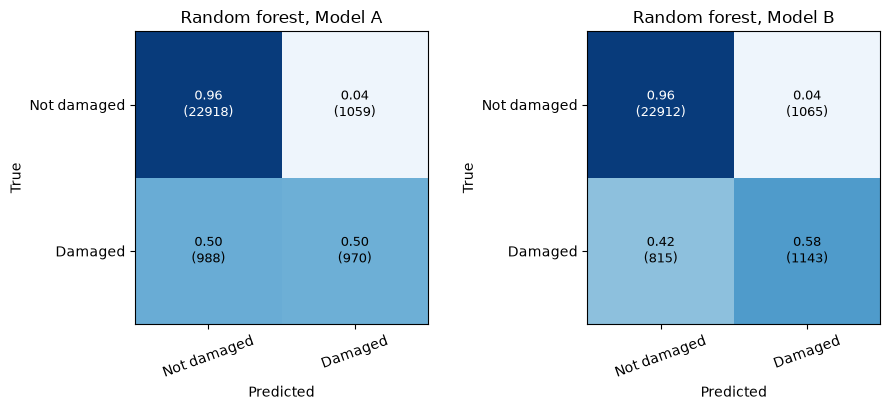

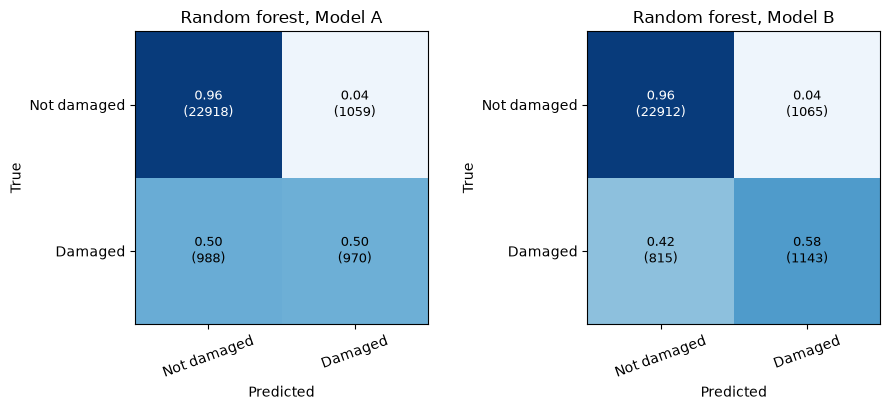

In [9]:
plot_confusion_matrices(
    {f"Random forest, Model {m}": binary_grids[f"Random Forest {m}"].best_estimator_ for m in ["A", "B"]},
    Xtest, ytest, "../plots/cm_binary.png", labels=BINARY_LABELS
)